# Brookfield exponential MaVaN plots

Compact notebook for the four Brookfield exponential-potential cases.
The CLASS runs remain explicit (model1 to model4) so that each case
can be changed independently.

The paper setup is three degenerate massive neutrinos, represented in
CLASS by one ncdm distribution with deg_ncdm = 3. 


In [1]:
from pathlib import Path

import classy
from classy import Class
import matplotlib.pyplot as plt
import numpy as np

print("classy:", classy.__file__)

def divide(numerator, denominator):
    '''Safe element-wise division.'''
    numerator, denominator = np.broadcast_arrays(
        numerator, denominator
    )
    result = np.full(numerator.shape, np.nan, dtype=float)

    valid = (
        np.isfinite(numerator)
        & np.isfinite(denominator)
        & (denominator != 0.0)
    )

    np.divide(
        numerator,
        denominator,
        out=result,
        where=valid
    )

    return result
    
# Numerical and plotting controls
K_H_MPC = np.geomspace(1.0e-5, 3.0, 1000)
Z_PK = 0.0
L_MAX = 2500
ELL_PLOT_MAX = 1500
Z_BACKGROUND_MAX = 10.0
Z_APPARENT_MAX = 2.0  # w_app can have a pole at higher redshift
W_NU_NR_MAX = 1.0e-2  # use NR m_eff diagnostic only when p_nu/rho_nu is small

MNU0_EV = 0.314
T_NCDM = 0.71611
T_CMB_UK = 2.7255e6

# Keep False for the first implementation diagnosis. Set True only for a
# secondary Halofit comparison after the linear results are understood.
USE_NONLINEAR_PK = False

SAVE_FIGURES = True
FIGURE_DIR = Path("plots_mavan")
if SAVE_FIGURES:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"axes.labelsize": 20})

classy: /home/gabriel/anaconda3/lib/python3.10/site-packages/classy/__init__.py


## CLASS parameters

These are the same Brookfield parameters used in the comparison
notebook. Only \(\beta\) and \(\lambda\) change between the four runs.


In [2]:
common_params = {
    "H0": 70.0,
    "omega_b": 0.02238280,
    "omega_cdm": 0.1201075,
    "A_s": 2.100549e-9,
    "n_s": 0.9660499,

    # One massive species with present mass m_nu,0 = 0.06 eV.
    "N_ur": 0.00441,
    "N_ncdm": 1,
    "m_ncdm": MNU0_EV,
    "T_ncdm": T_NCDM,
    "deg_ncdm": 3,

    "Omega_fld": 0.0,
    "Omega_Lambda": 0.0,
    "Omega_scf": -1,
    "scf_tuning_index": 1,
    "attractor_ic_scf": "no",

    "output": "mPk,tCl,pCl,lCl",
    "lensing": "yes",
    "l_max_scalars": L_MAX,
    "P_k_max_h/Mpc": 1.05 * K_H_MPC[-1],
    "non_linear": "halofit" if USE_NONLINEAR_PK else "none",
    "gauge": "synchronous",
    "ncdm_fluid_approximation": 3,
    "get_perturbations_in_current_gauge": "yes",
    # Paper Fig. 11 stability scale
    "k_output_values": str(2.3e-6), 
}

# scf_parameters = lambda, shooting guess for log10(V0), phi_ini, phi'_ini
params1 = {
    **common_params,
    "beta_ncdm": 0.0,
    "scf_parameters": "1.0, -7.0, 0.0, 0.0",
}
params2 = {
    **common_params,
    "beta_ncdm": 1.0,
    "scf_parameters": "1.0, -7.0, 0.0, 0.0",
}
params3 = {
    **common_params,
    "beta_ncdm": -0.79,
    "scf_parameters": "1.0, -7.0, 0.0, 0.0",
}
params4 = {
    **common_params,
    "beta_ncdm": 1.0,
    "scf_parameters": "0.5, -7.0, 0.0, 0.0",
}

labels = (
    r"$\beta=0,\ \lambda=1$",
    r"$\beta=1,\ \lambda=1$",
    r"$\beta=-0.79,\ \lambda=1$",
    r"$\beta=1,\ \lambda=0.5$",
)
colors = ("black", "tab:blue", "tab:green", "tab:red")
linestyles = ("-", "--", ":", "-.")


## Run the four models


In [3]:
model1 = Class()
model1.set(params1)
model1.compute()

model2 = Class()
model2.set(params2)
model2.compute()

model3 = Class()
model3.set(params3)
model3.compute()

model4 = Class()
model4.set(params4)
model4.compute()

models = (model1, model2, model3, model4)
parameters = (params1, params2, params3, params4)
print("All four CLASS models completed.")


All four CLASS models completed.


## Background quantities

The complete interacting scalar equation of state is

$
w_{\phi,\mathrm{eff}}
=w_\phi+
\frac{\beta}{3}\frac{d\phi}{d\ln a}
\frac{\rho_\nu-3p_\nu}{\rho_\phi}.
$

The apparent fluid subtracts the density and pressure of a neutrino
component whose mass is incorrectly assumed to have always equaled its
present value:

$
w_{\mathrm{app}}=
\frac{p_\phi+p_\nu-p_{\nu,\mathrm{const}}}
{\rho_\phi+\rho_\nu-\rho_{\nu,\mathrm{const}}}.
$


In [4]:
def background_data(model, beta):
    bg = model.get_background()
    z = bg["z"]
    a = 1.0 / (1.0 + z)
    H = bg["H [1/Mpc]"]
    phi = bg["phi_scf"]
    phi_prime = bg["phi'_scf"]
    rho_phi = bg["(.)rho_scf"]
    p_phi = bg["(.)p_scf"]
    rho_nu = bg["(.)rho_ncdm[0]"]
    p_nu = bg["(.)p_ncdm[0]"]

    #scalar field quantities
    phi_scf = bg['phi_scf']
    dphi_scf = bg['phi\'_scf']
    rho_scf = bg['(.)rho_scf']
    p_scf = bg['(.)p_scf']
    V_scf = bg['V_scf']
    ddV_scf = bg['V\'\'_scf']
    w_phi = p_scf/rho_scf

    # phi0 is the CURRENT value (at z=0, which is the LAST element)
    phi0 = phi_scf[-1]

    # Complete expression: valid in both relativistic and NR regimes.
    H_conf = a * H

    w_phi_eff = w_phi + (
        beta * dphi_scf * (rho_nu - 3*p_nu)
    ) / (3 * H_conf * rho_scf)

    # ---------------------------------------------------------
    # Apparent equation of state
    #
    # Brookfield et al.:
    #
    # w_app = w_phi / (1 - x)
    #
    # x = -rho_nu0/(a^3 rho_phi)
    #     * [m_nu(phi)/m_nu(phi0) - 1]
    # ---------------------------------------------------------

    mnu_ratio = np.exp(np.clip(beta * (phi - phi0),-700.0,700.0)
    )

    rho_nu0 = rho_nu[-1]

    x_app = -(rho_nu0 / (a**3 * rho_phi)) * (mnu_ratio - 1.0)

    w_app = w_phi / (1.0 - x_app)

    # Call gravitational potential
    
    sources, k_array, tau_array = model.get_sources()
    
    k_target = 1e-3  # Mpc^-1
    k_index = np.argmin(np.abs(k_array - k_target))
    
    phi_plus_psi = np.asarray(
        sources["phi_plus_psi"][k_index],
        dtype=float,
    )
    
    z_array = np.asarray(
        model.z_of_tau(tau_array),
        dtype=float,
    )
    
    a_array = 1.0 / (1.0 + z_array)

    # Compute m_eff^2
    m_eff_squared = ddV_scf + 3.0 * beta**2 * (rho_nu - 3*p_nu)

    # Compute the ratio
    meff_over_H = np.sqrt(
        np.where(m_eff_squared >= 0.0, m_eff_squared, np.nan)
    ) / H

    return {
        "z": z,
        "a": a,
        "a_array":a_array,
        "phi": phi,
        "phi_prime": phi_prime,
        "phi0": phi0,
        "rho_phi": rho_phi,
        "p_phi": p_phi,
        "rho_nu": rho_nu,
        "p_nu": p_nu,
        "w_phi": w_phi,
        "w_phi_eff": w_phi_eff,
        "w_app": w_app,
        "x_app": x_app,
        "p_plus_psi": phi_plus_psi,
        "meff_over_H": meff_over_H,
        "mnu": MNU0_EV * mnu_ratio,
    }
    
data1 = background_data(model1, params1["beta_ncdm"])
data2 = background_data(model2, params2["beta_ncdm"])
data3 = background_data(model3, params3["beta_ncdm"])
data4 = background_data(model4, params4["beta_ncdm"])
data = (data1, data2, data3, data4)


In [5]:
def neutrino_sound_speed_data(model):
    pert = model.get_perturbations()

    mode = pert["scalar"][0]

    a = np.asarray(mode["a"], dtype=float)
    cs2_nu = np.asarray(
        mode["cs2_ncdm[0]"], dtype=float
    )
    delta_nu = np.asarray(
        mode["delta_ncdm[0]"], dtype=float
    )

    return {
        "a": a,
        "z": 1.0/a - 1.0,
        "cs2_nu": cs2_nu,
        "delta_nu": delta_nu,
    }


cs1 = neutrino_sound_speed_data(model1)
cs2 = neutrino_sound_speed_data(model2)
cs3 = neutrino_sound_speed_data(model3)
cs4 = neutrino_sound_speed_data(model4)

sound_data = (cs1, cs2, cs3, cs4)

## Spectra


In [6]:
spectra = []
for model in models:
    h = model.h()

    cls = model.lensed_cl(L_MAX)
    ell = np.asarray(cls["ell"], dtype=int)
    cl_tt = np.asarray(cls["tt"], dtype=float)
    dl_tt = ell * (ell + 1.0) * cl_tt * T_CMB_UK**2 / (2.0 * np.pi)

    pk = np.asarray(
        model.get_pk_all(
            K_H_MPC * h,
            Z_PK,
            nonlinear=USE_NONLINEAR_PK,
        ),
        dtype=float,
    ).squeeze() * h**3

    spectra.append({"ell": ell, "dl_tt": dl_tt, "pk": pk})


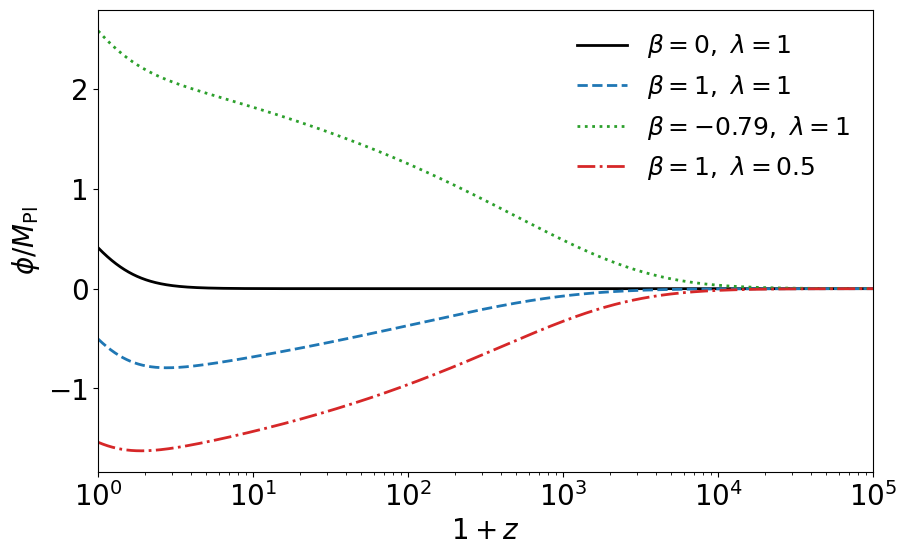

In [7]:
fig, ax = plt.subplots(
    figsize=(10, 6))

for result, label, color, ls in zip(
    data, labels, colors, linestyles
):
    order = np.argsort(result["z"])
    z = result["z"][order]
    mask = z <= 1.0e6

    ax.semilogx(
        1.0 + z[mask],
        result["phi"][order][mask],
        color=color,
        linestyle=ls,
        linewidth=2,
        label=label,
    )

ax.set_xlabel(r"$1+z$", fontsize=20)
ax.set_ylabel(r"$\phi/M_{\rm Pl}$", fontsize=20)
ax.set_xlim(1.0, 1.0e5)

ax.tick_params(axis="both", which="major", labelsize=20)
ax.legend(fontsize=18, frameon=False)

if SAVE_FIGURES:
    fig.savefig(
        FIGURE_DIR / "phi_vs_z.pdf",
        bbox_inches="tight"
    )
    fig.savefig(
        FIGURE_DIR / "phi_vs_z.png",
        dpi=220,
        bbox_inches="tight"
    )

plt.show()

## Effective neutrino mass


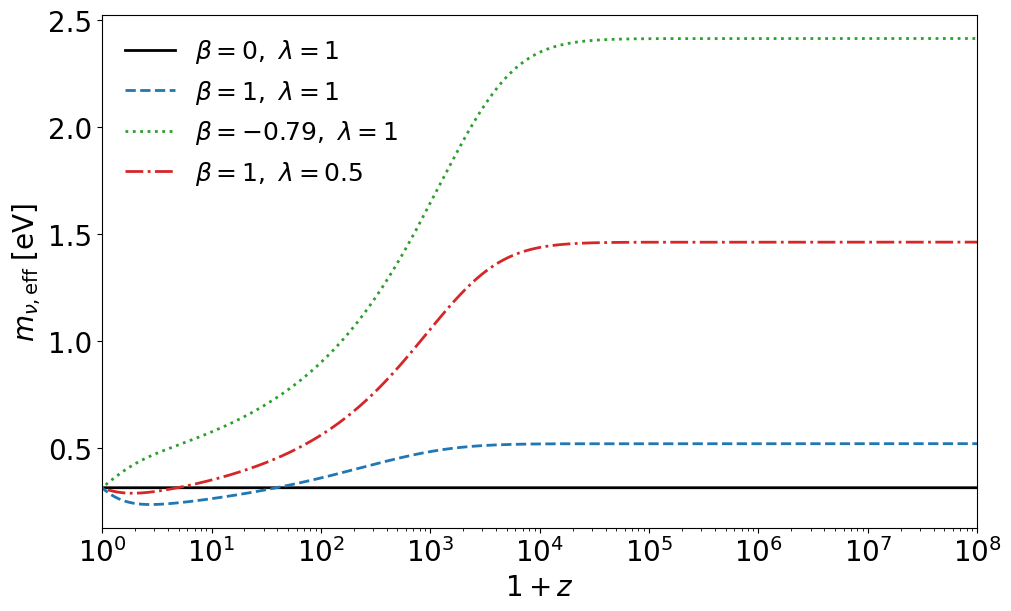

In [8]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

for result, label, color, ls in zip(
    data, labels, colors, linestyles
):
    ax.semilogx(
        1.0 + result["z"], result["mnu"],
        color=color, linestyle=ls, linewidth=2, label=label,
    )

ax.set(
    xlabel=r"$1+z$",
    ylabel=r"$m_{\nu,\mathrm{eff}}\;[\mathrm{eV}]$",
    xlim=(1.0, 1.0e8), 
)
ax.xaxis.label.set_fontsize(20)
ax.yaxis.label.set_fontsize(20)
ax.tick_params(axis="both", which="major", labelsize=20)
ax.legend(fontsize=18, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "m_eff_vs_z.pdf", bbox_inches="tight")
plt.show()


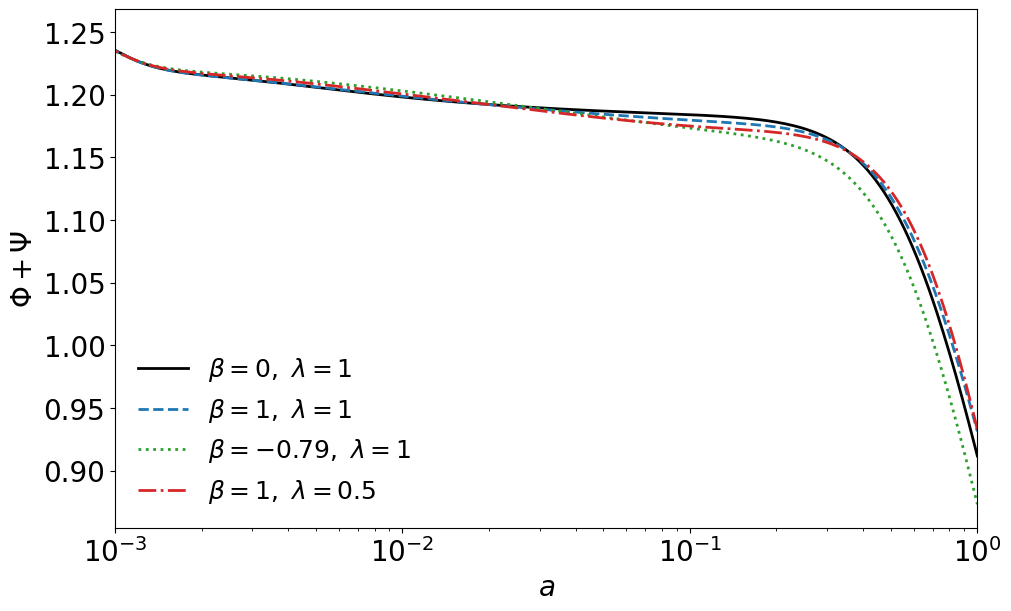

In [9]:
fig, ax = plt.subplots(
    figsize=(10, 6),
    layout="constrained",
)

for result, label, color, ls in zip(
    data, labels, colors, linestyles
):
    a = np.asarray(result["a_array"])
    phi_plus_psi = np.asarray(result["p_plus_psi"])

    finite = (
        np.isfinite(a)
        & np.isfinite(phi_plus_psi)
        & (a > 0.0)
    )

    a = a[finite]
    phi_plus_psi = phi_plus_psi[finite]

    order = np.argsort(a)

    ax.semilogx(
        a[order],
        phi_plus_psi[order],
        color=color,
        linestyle=ls,
        linewidth=2,
        label=label,
    )

ax.set_xlabel(r"$a$",fontsize=20)
ax.set_ylabel(r"$\Phi+\Psi$",fontsize=20)

ax.set_xlim(1.0e-3, 1.0)

ax.tick_params(axis="both", which="major", labelsize=20)
ax.legend(fontsize=18, frameon=False)

if SAVE_FIGURES:
    fig.savefig(
        FIGURE_DIR / "phi_plus_psi_vs_a.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURE_DIR / "phi_plus_psi_vs_a.png",
        dpi=220,
        bbox_inches="tight",
    )

plt.show()

## CMB temperature spectrum $D_\ell^{TT}$


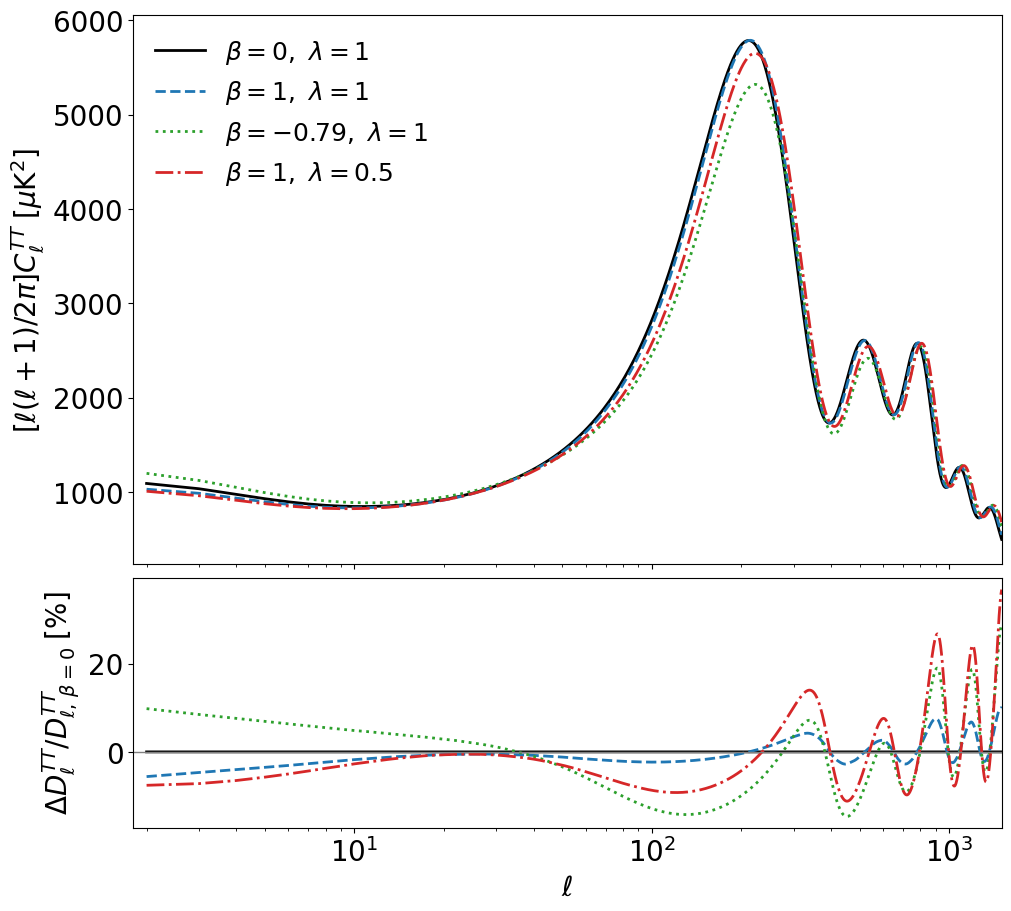

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1.0]},
                         layout="constrained")

reference = spectra[0]
for spectrum, label, color, ls in zip(
    spectra, labels, colors, linestyles
):
    mask = (spectrum["ell"] >= 2) & (spectrum["ell"] <= ELL_PLOT_MAX)
    ell = spectrum["ell"][mask]
    dl = spectrum["dl_tt"][mask]
    dl_ref = np.interp(ell, reference["ell"], reference["dl_tt"])

    axes[0].semilogx(
        ell, dl, color=color, linestyle=ls, linewidth=2, label=label,
    )
    axes[1].semilogx(
        ell, 100.0 * (divide(dl, dl_ref) - 1.0),
        color=color, linestyle=ls, linewidth=2,
    )

axes[0].set_ylabel(
    r"$[\ell(\ell+1)/2\pi]C_\ell^{TT}\;[\mu\mathrm{K}^2]$"
)

axes[1].set(
    xlabel=r"$\ell$",
    ylabel=r"$\Delta D_\ell^{TT}/D_{\ell,\,\beta=0}^{TT}\;[\%]$",
    xlim=(1.8, ELL_PLOT_MAX),
)
axes[1].xaxis.label.set_fontsize(20)
axes[0].yaxis.label.set_fontsize(20)

axes[1].axhline(0.0, color="0.5", linewidth=1.0)
for ax in axes:
    ax.tick_params(axis="both", which="major", labelsize=20)
axes[0].legend(fontsize=18, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "cltt_mavan.pdf", bbox_inches="tight")
    fig.savefig(FIGURE_DIR / "cltt_mavan.png", dpi=220,
                bbox_inches="tight")
plt.show()


## Linear matter power spectrum


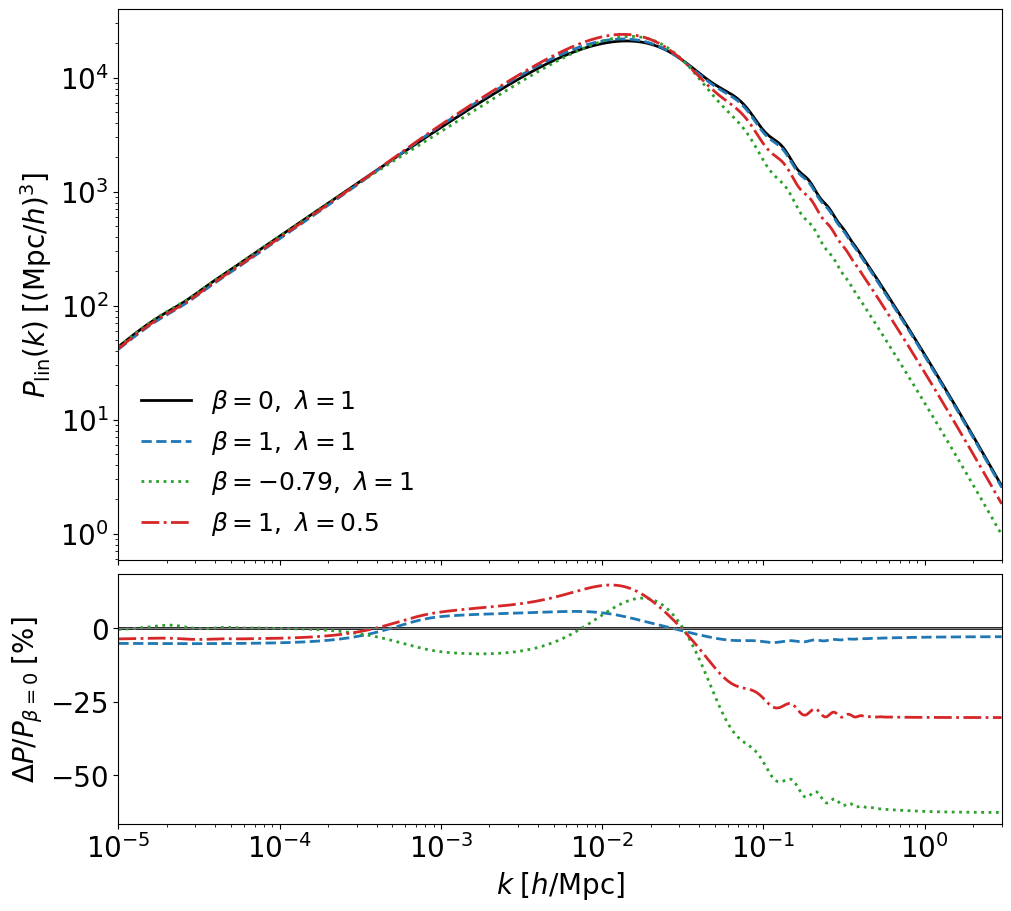

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1.0]},
                         layout="constrained")

reference_pk = spectra[0]["pk"]
for spectrum, label, color, ls in zip(
    spectra, labels, colors, linestyles
):
    axes[0].loglog(
        K_H_MPC, spectrum["pk"],
        color=color, linestyle=ls, linewidth=2, label=label,
    )
    axes[1].semilogx(
        K_H_MPC, 100.0 * (divide(spectrum["pk"], reference_pk) - 1.0),
        color=color, linestyle=ls, linewidth=2,
    )

pk_label = r"$P_{\rm NL}(k)\;[(\mathrm{Mpc}/h)^3]$" if USE_NONLINEAR_PK \
    else r"$P_{\rm lin}(k)\;[(\mathrm{Mpc}/h)^3]$"
axes[0].set_ylabel(pk_label)
axes[1].set(
    xlabel=r"$k\;[h/\mathrm{Mpc}]$",
    ylabel=r"$\Delta P/P_{\beta=0}\;[\%]$",
    xlim=(K_H_MPC[0], K_H_MPC[-1]),
)

axes[1].xaxis.label.set_fontsize(20)
axes[0].yaxis.label.set_fontsize(20)
axes[1].axhline(0.0, color="0.5", linewidth=1.0)
for ax in axes:
    ax.tick_params(axis="both", which="major", labelsize=20)
axes[0].legend(fontsize=18, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "pk_mavan.pdf", bbox_inches="tight")
    fig.savefig(FIGURE_DIR / "pk_mavan.png", dpi=220,
                bbox_inches="tight")
plt.show()


## Intrinsic, interacting-effective, and apparent equations of state


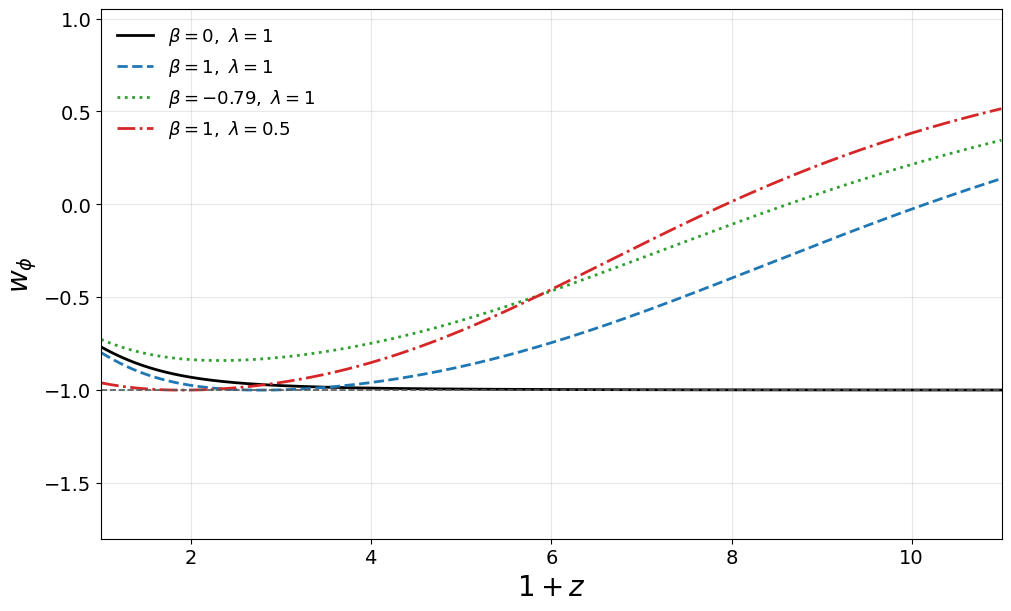

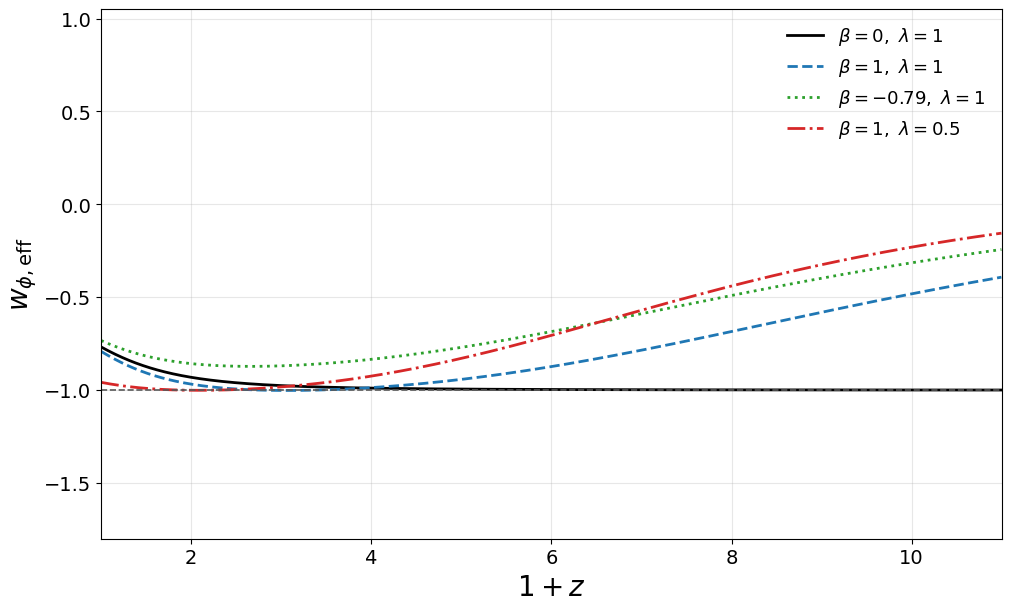

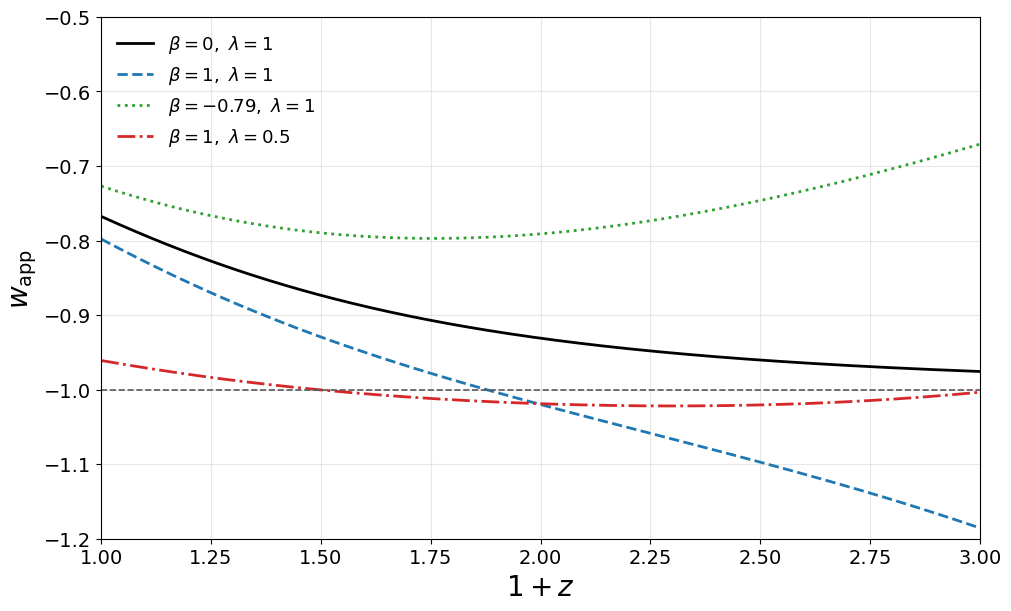

In [12]:
def plot_eos(key, ylabel, filename, zmax, ylim):
    fig, ax = plt.subplots(
        figsize=(10, 6),
        layout="constrained",
    )

    for result, label, color, ls in zip(
        data, labels, colors, linestyles
    ):
        mask = (
            (result["z"] >= 0.0)
            & (result["z"] <= zmax)
        )

        order = np.argsort(result["z"][mask])

        z = result["z"][mask][order]
        eos = result[key][mask][order]

        ax.plot(
            1.0 + z,
            eos,
            color=color,
            linestyle=ls,
            linewidth=2,
            label=label,
        )

    ax.set_xlabel(r"$1+z$")
    ax.set_ylabel(ylabel)

    ax.set_xlim(1.0, 1.0 + zmax)
    ax.set_ylim(ylim)

    ax.axhline(
        -1.0,
        color="0.35",
        linestyle="--",
        linewidth=1.2,
    )

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=14,
    )

    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=13, frameon=False)

    if SAVE_FIGURES:
        fig.savefig(
            FIGURE_DIR / filename,
            bbox_inches="tight",
        )

    plt.show()


plot_eos(
    "w_phi",
    r"$w_\phi$",
    "w_phi_eos.pdf",
    Z_BACKGROUND_MAX,
    (-1.8, 1.05),
)

plot_eos(
    "w_phi_eff",
    r"$w_{\phi,\mathrm{eff}}$",
    "w_phi_eff_eos.pdf",
    Z_BACKGROUND_MAX,
    (-1.8, 1.05),
)

plot_eos(
    "w_app",
    r"$w_{\mathrm{app}}$",
    "w_app_eos.pdf",
    Z_APPARENT_MAX,
    (-1.2, -0.5),
)

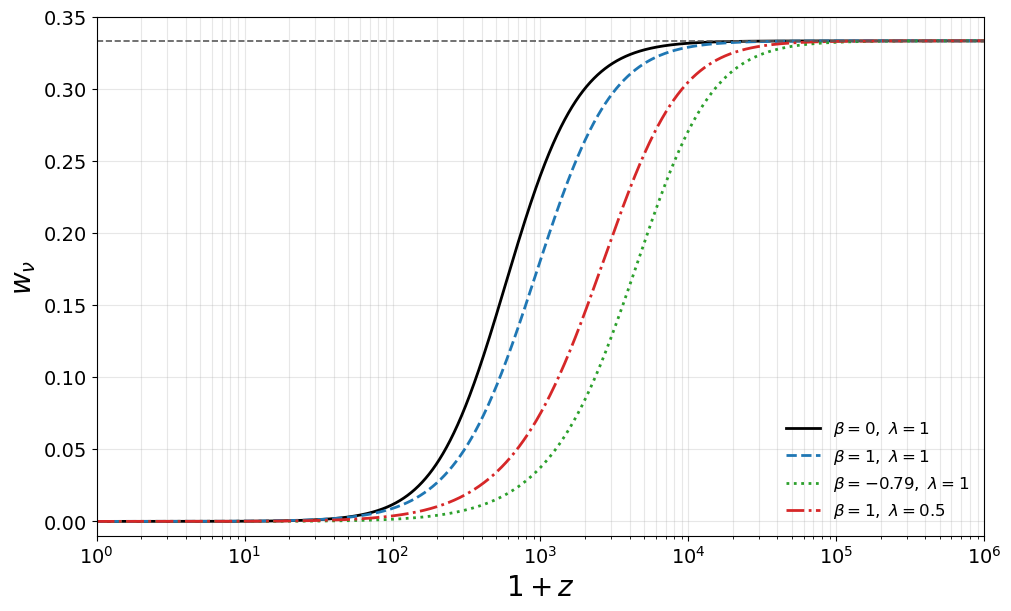

In [13]:
fig, ax = plt.subplots(
    figsize=(10, 6),
    layout="constrained"
)

for result, label, color, ls in zip(
    data, labels, colors, linestyles
):
    order = np.argsort(result["z"])
    z = result["z"][order]

    mask = (z >= 0.0) & (z <= 1.0e8)

    rho_nu = result["rho_nu"][order][mask]
    p_nu = result["p_nu"][order][mask]

    w_nu = p_nu / rho_nu

    ax.semilogx(
        1.0 + z[mask],
        w_nu,
        color=color,
        linestyle=ls,
        linewidth=2,
        label=label,
    )

ax.set_xlabel(r"$1+z$")
ax.set_ylabel(r"$w_\nu$")
ax.set_xlim(1.0, 1.0e6)
ax.set_ylim(-0.01, 0.35)

# Relativistic limit
ax.axhline(
    1.0 / 3.0,
    color="0.35",
    linestyle="--",
    linewidth=1.2,
)

ax.tick_params(axis="both", which="major", labelsize=14)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=12, frameon=False)

if SAVE_FIGURES:
    fig.savefig(
        FIGURE_DIR / "w_nu_vs_z.pdf",
        bbox_inches="tight"
    )
    fig.savefig(
        FIGURE_DIR / "w_nu_vs_z.png",
        dpi=220,
        bbox_inches="tight"
    )

plt.show()

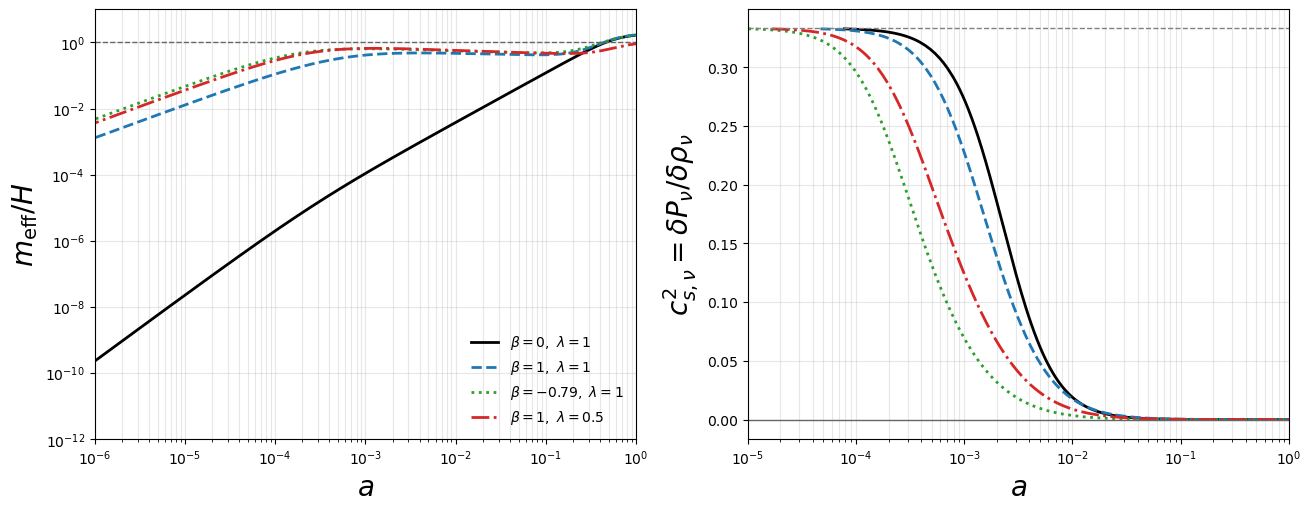

In [14]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    layout="constrained",
)

for result, sound, label, color, ls in zip(
    data,
    sound_data,
    labels,
    colors,
    linestyles
):

    axes[0].loglog(
        result["a"],
        result["meff_over_H"],
        color=color,
        linestyle=ls,
        linewidth=2,
        label=label,
    )

    axes[1].semilogx(
        sound["a"],
        sound["cs2_nu"],
        color=color,
        linestyle=ls,
        linewidth=2,
        label=label,
    )


# m_eff/H
axes[0].axhline(
    1.0,
    color="0.4",
    linestyle="--",
    linewidth=1,
)

axes[0].set(
    xlabel=r"$a$",
    ylabel=r"$m_{\rm eff}/H$",
    xlim=(1e-6, 1e0),
    ylim=(1e-12, 1e1)
)


# neutrino sound speed
axes[1].axhline(
    0.0,
    color="0.4",
    linewidth=1,
)

axes[1].axhline(
    1.0/3.0,
    color="0.5",
    linestyle="--",
    linewidth=1,
)

axes[1].set(
    xlabel=r"$a$",
    ylabel=r"$c_{s,\nu}^2=\delta P_\nu/\delta\rho_\nu$",
    xlim=(1e-5, 1.0),
)

for ax in axes:
    ax.grid(
        True,
        which="both",
        alpha=0.3
    )

axes[0].legend(frameon=False)

plt.show()

In [15]:
def finite_range(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    return (np.min(values), np.max(values)) if values.size else (np.nan, np.nan)


for result, spectrum, label in zip(data, spectra, labels):
    late = (result["z"] >= 0.0) & (result["z"] <= Z_BACKGROUND_MAX)
    w_eff_min, w_eff_max = finite_range(result["w_phi_eff"][late])
    apparent = (result["z"] >= 0.0) & (result["z"] <= Z_APPARENT_MAX)
    w_app_min, w_app_max = finite_range(result["w_app"][apparent])
    pk_delta = 100.0 * (divide(spectrum["pk"], spectra[0]["pk"]) - 1.0)

    ell_mask = (spectrum["ell"] >= 2) & (spectrum["ell"] <= ELL_PLOT_MAX)
    dl_ref = np.interp(
        spectrum["ell"][ell_mask],
        spectra[0]["ell"], spectra[0]["dl_tt"],
    )
    cl_delta = 100.0 * (
        divide(spectrum["dl_tt"][ell_mask], dl_ref) - 1.0
    )

    print("\n", label)
    print("  min(phi) =", np.min(result["phi"]))
    print("  phi(z=0) =", result["phi0"])
    earliest = np.argmax(result["z"])
    today = np.argmin(np.abs(result["z"]))
    print(
        "  m_nu earliest / today [eV] =",
        result["mnu"][earliest], result["mnu"][today],
    )
    print("  w_phi_eff range, 0<=z<=10 =", (w_eff_min, w_eff_max))
    print(f"  w_app range, 0<=z<={Z_APPARENT_MAX:g} =", (w_app_min, w_app_max))
    print("  max |Delta P/P_ref| [%] =", np.nanmax(np.abs(pk_delta)))
    print("  max |Delta D_ell/D_ell,ref| [%] =", np.nanmax(np.abs(cl_delta)))




 $\beta=0,\ \lambda=1$
  min(phi) = 0.0
  phi(z=0) = 0.4094010858412566
  m_nu earliest / today [eV] = 0.314 0.314
  w_phi_eff range, 0<=z<=10 = (-0.999463225132251, -0.767641742314168)
  w_app range, 0<=z<=2 = (-0.975678756308601, -0.767641742314168)
  max |Delta P/P_ref| [%] = 0.0
  max |Delta D_ell/D_ell,ref| [%] = 0.0

 $\beta=1,\ \lambda=1$
  min(phi) = -0.7924098198039646
  phi(z=0) = -0.5047159866483019
  m_nu earliest / today [eV] = 0.5201457041195142 0.314
  w_phi_eff range, 0<=z<=10 = (-1.0018967220553439, -0.3919886437698858)
  w_app range, 0<=z<=2 = (-1.185523420394027, -0.7980079799405263)
  max |Delta P/P_ref| [%] = 5.82690937627397
  max |Delta D_ell/D_ell,ref| [%] = 10.004728268611718

 $\beta=-0.79,\ \lambda=1$
  min(phi) = 0.0
  phi(z=0) = 2.5824200268146087
  m_nu earliest / today [eV] = 2.415121335075341 0.314
  w_phi_eff range, 0<=z<=10 = (-0.8721611168241965, -0.24310906447687675)
  w_app range, 0<=z<=2 = (-0.797209726929912, -0.67083819871527)
  max |Delta P/P_r